# 05 · Image model

This notebook presents the image model. Training runs as scripts (`src/`), because on Windows the data loader's
worker processes must import the dataset code from a module; this notebook reads the saved results and figures,
so it runs in seconds.

| Step | Command | Output |
|---|---|---|
| Index and splits | `python -m src.build_index --resize-pad` | `data/splits/image_index.csv` |
| ISIC training, 3 seeds | `python -m src.train --seed 42` (and 1, 2) | `models/convnext_milk_s*.pt` |
| PAD fine-tuning, 2 variants × 3 seeds | `python -m src.finetune_pad --seed 42 [--scc-boost 2]` | `models/convnext_pad_s*.pt` |
| Cheap baseline | `python -m src.baseline_dinov2` | `reports/baseline_dinov2_pad_val.json` |
| Final evaluation | `python -m src.evaluate` | `reports/final_results.json`, `reports/figures/` |
| Leakage audit | `python -m src.near_duplicates` | `reports/near_duplicates_pad.json` |
| Single test run, after the freeze | `python -m src.evaluate_test --frozen` | `reports/test_results.json` |

**PAD test patients are not loaded here.** The final model is the 60/40 fusion (`reports/decisions.md`). Everything below is on the 220 PAD validation patients of the frozen split
(notebook 02).

In [4]:
# Cell 1 · Configuration
# This notebook computes nothing: it reads the artefacts the scripts in src/ wrote on the training
# machine. In a repo checkout it sits in notebooks/ and the root is one level up; in Colab it reads
# the project folder on Drive. Both work, so the notebook runs in either place.
import os, sys, json
from pathlib import Path
import pandas as pd
from IPython.display import Image, display, Markdown

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
    ROOT = Path("/content/drive/MyDrive/לימודים/Data Science/Skin Lesion Triage for Healthcare Providers")
else:
    ROOT = Path("..").resolve()

pd.set_option("display.precision", 3)

NEEDED = [
    ROOT / "reports" / "final_results.json",
    ROOT / "reports" / "near_duplicates_pad.json",
    ROOT / "data" / "splits" / "image_index.csv",
    ROOT / "reports" / "figures" / "sensitivity_vs_slots.png",
    ROOT / "reports" / "figures" / "training_curves.png",
    ROOT / "reports" / "figures" / "confusion_matrix_pad_val.png",
]
missing = [p for p in NEEDED if not p.exists()]
if missing:
    raise FileNotFoundError(
        f"root = {ROOT}\nmissing {len(missing)} of {len(NEEDED)} artefacts:\n  "
        + "\n  ".join(str(p.relative_to(ROOT)) for p in missing)
        + "\nCopy them from the image-model branch (reports/ and data/splits/).")

R = json.loads((ROOT / "reports" / "final_results.json").read_text())
print("project root:", ROOT)
print("PAD validation patients:", R["pad_val_patients"])

Mounted at /content/drive
project root: /content/drive/MyDrive/לימודים/Data Science/Skin Lesion Triage for Healthcare Providers
PAD validation patients: 220


## 1 · Label space

The model predicts 6 classes. Two scores are derived from the same probabilities: the **cancer score**
P(MEL)+P(SCC)+P(BCC), the charter's M2 definition, used for ranking; and the urgent score P(MEL)+P(SCC).

In [5]:
idx = pd.read_csv(ROOT / "data" / "splits" / "image_index.csv", dtype=str).fillna("")
pd.crosstab(idx["split"], idx["label6"].replace("", "-"), margins=True)

label6,-,AK,BCC,BKL,MEL,NEV,SCC,All
split,,,,,,,,
excluded,208,0,2,0,0,0,0,210
milk_train,0,106,2151,466,397,641,564,4325
milk_val,0,17,398,72,67,105,104,763
msk_eval,1220,0,0,0,6,15,0,1241
pad_test,0,153,196,49,9,61,33,501
pad_train,0,473,515,156,35,136,125,1440
pad_val,0,104,134,30,8,47,34,357
All,1428,853,3396,773,522,1005,860,8837


## 2 · Decision rules, written before the runs

In [6]:
print(R["rules"])

Final evaluation on PAD validation patients. PAD test patients are never loaded.

Applies the decision rules written down before the runs:
  1. SCC weight x2 is adopted only if, averaged over the 3 seeds, fewer SCC photos are called AK and the
     patient AUC drops by no more than 0.01.
  2. The final model is the seed-42 run of the adopted variant, not the best seed.
  3. Averaging the 3 seeds is adopted only if its paired AUC gain over the single model excludes zero.
  4. Fusion with the questionnaire uses fixed weights, 60% image / 40% questionnaire.
After these results the team chose the 60/40 fusion as the final model (reports/decisions.md); the manifest
records it. Validation numbers are slightly optimistic: epochs and the rules above were chosen on them.


## 3 · Three seeds, two variants

Each variant was trained three times (seeds 42, 1, 2). The table shows the mean and the range over seeds.

In [7]:
rows = []
for v, s in R["seed_summary"].items():
    rows.append({"variant": v, **{f"{k} mean": s[k]["mean"] for k in s}, "AUC min": s["auc"]["min"], "AUC max": s["auc"]["max"]})
display(pd.DataFrame(rows).set_index("variant"))
print("SCC boost decision:", R["decision_scc_boost"])
print("Ensemble decision :", R["decision_ensemble"])

,auc mean,sens_primary mean,scc_recall mean,scc_called_ak mean,melanoma_patients_flagged mean,AUC min,AUC max
variant,,,,,,,
plain,0.953,0.615,0.412,7.333,2.667,0.950,0.959
scc_x2,0.950,0.599,0.520,5.667,2.000,0.947,0.956


SCC boost decision: {'adopted': True, 'variant': 'scc_x2'}
Ensemble decision : {'adopted': False, 'auc_gain_mean': 0.0005702846236826767, 'auc_gain_ci': [-0.00738527922993937, 0.008466102398141297], 'ensemble_auc': 0.956103227947888, 'single_auc': 0.9556053439548585}


## 4 · Baseline table (charter section 4)

Same 220 patients for every row. Sensitivity and PPV at the primary operating point: 10 urgent slots for 100
daily arrivals, 10% malignant prevalence.

In [8]:
def row(name, r):
    if r is None:
        return {"model": name, "patient AUC": 0.5, "AUC 95% CI": "", "sensitivity": 0.10, "PPV": 0.10}
    p = next(s for s in r["scenarios"] if s["slots"] == 10 and s["prevalence"] == 0.10)
    return {"model": name, "patient AUC": r["auc"], "AUC 95% CI": f"{r['auc_ci'][0]:.3f}-{r['auc_ci'][1]:.3f}",
            "sensitivity": p["sensitivity"], "PPV": p["ppv"]}
pd.DataFrame([row("Arrival order (today)", None), row("Questionnaire", R["questionnaire"]),
              row("DINOv2 + logistic regression", R["dinov2_logreg"]), row("ConvNeXt, ISIC only", R["image_isic_only"]),
              row("ConvNeXt + PAD fine-tune (image part)", R["final_image_model"]),
              row("Final: image 60% + questionnaire 40%", R["fused"])]).set_index("model")

,patient AUC,AUC 95% CI,sensitivity,PPV
model,,,,
Arrival order (today),0.500,,0.100,0.100
Questionnaire,0.867,0.815-0.913,0.524,0.532
DINOv2 + logistic regression,0.880,0.835-0.923,0.485,0.513
"ConvNeXt, ISIC only",0.778,0.719-0.836,0.301,0.303
ConvNeXt + PAD fine-tune (image part),0.956,0.930-0.977,0.602,0.610
Final: image 60% + questionnaire 40%,0.954,0.928-0.978,0.612,0.614


In [9]:
for k in ("image_minus_questionnaire", "fused_minus_questionnaire", "fused_minus_image"):
    print(f"{k:<28} AUC {R[k]['mean']:+.3f}  (95% CI {R[k]['ci'][0]:+.3f} to {R[k]['ci'][1]:+.3f})")

image_minus_questionnaire    AUC +0.089  (95% CI +0.047 to +0.132)
fused_minus_questionnaire    AUC +0.087  (95% CI +0.054 to +0.124)
fused_minus_image            AUC -0.001  (95% CI -0.014 to +0.011)


### Patients whose lesions were all biopsied

In PAD every cancer was biopsied; lesions without a biopsy are all benign and easy. Without them the numbers
drop for every model, and the order stays the same.

In [10]:
b = R["biopsied_only"]
print(f"{b['n_patients']} patients, {b['n_malignant']} with cancer")
pd.Series({k: b[f"auc_{k}"] for k in ("image", "questionnaire", "fused")}).to_frame("patient AUC")

116 patients, 93 with cancer


,patient AUC
image,0.886
questionnaire,0.846
fused,0.890


## 5 · How many cancer patients make the daily list

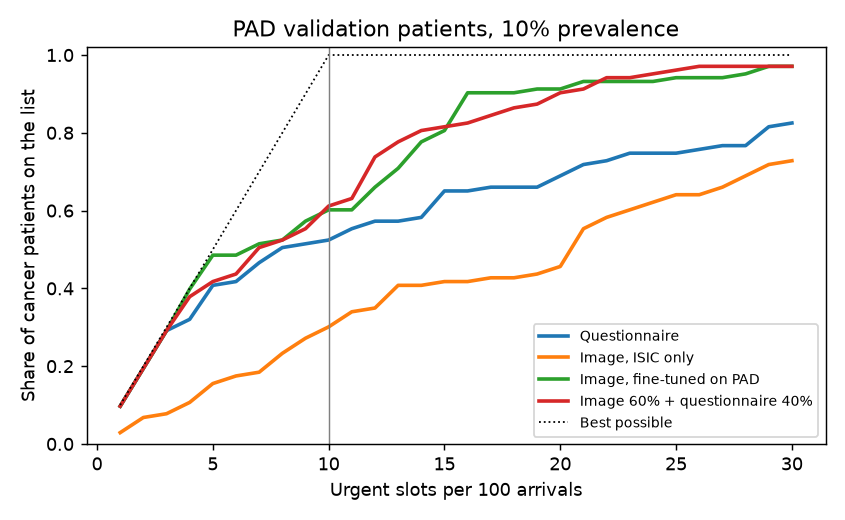

In [11]:
display(Image(filename=str(ROOT / "reports" / "figures" / "sensitivity_vs_slots.png")))

In [12]:
pd.DataFrame(R["fusion_weight_sweep"]).T.rename_axis("image weight")

,auc,sens_primary
image weight,,
0.0,0.867,0.524
0.4,0.936,0.612
0.5,0.947,0.612
0.6,0.954,0.612
0.7,0.957,0.563
1.0,0.956,0.602


## 6 · Training curves (seed 42)

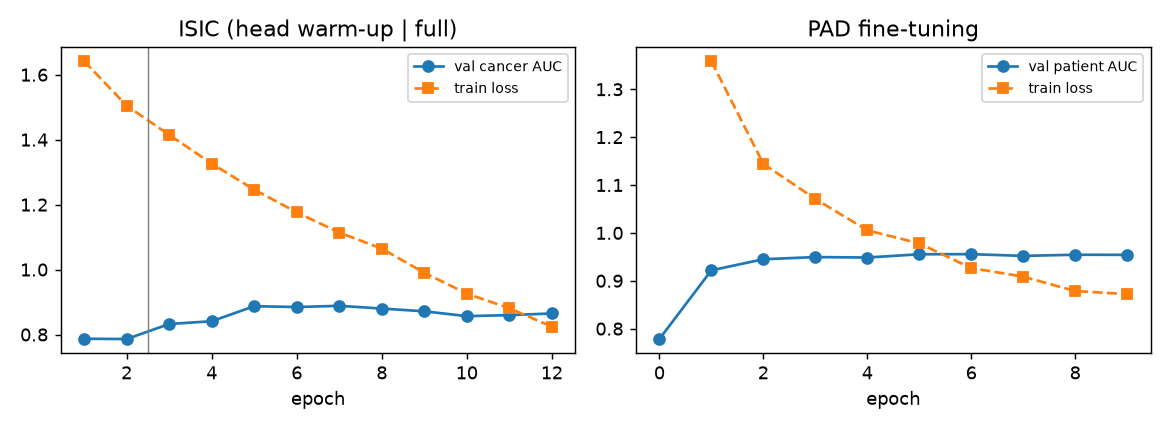

In [13]:
display(Image(filename=str(ROOT / "reports" / "figures" / "training_curves.png")))

## 7 · Where the model is wrong

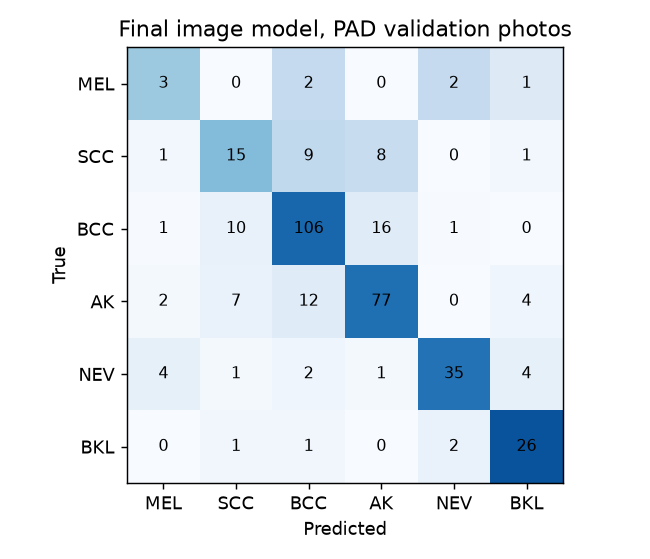

SCC photos called AK: 8 of 34 | melanoma patients on the list: 3 of 6


In [14]:
display(Image(filename=str(ROOT / "reports" / "figures" / "confusion_matrix_pad_val.png")))
f = R["final_image_model"]
print("SCC photos called AK:", f["scc_called_ak"], "of", f["n_scc"], "| melanoma patients on the list:",
      f["melanoma_patients_flagged"], "of", f["n_melanoma_patients"])

## 8 · Where the fine-tuning gain comes from, and leakage checks

In [15]:
display(pd.Series(R["diagnostics"]).to_frame("value"))
nd = json.loads((ROOT / "reports" / "near_duplicates_pad.json").read_text())
print(f"near-identical photos across PAD splits: {nd['hash_candidates']} hash candidates, {len(nd['confirmed_pairs'])} confirmed")
print("MSK benign false alarms at the primary cutoff:", R["msk_false_alarms"])

,value
isic_only_auc_without_ak_patients,0.899
final_auc_without_ak_patients,0.986
n_patients_without_ak,139.000
final_auc_mean_aggregation,0.937
final_auc_image_level,0.928
images_per_patient_auc,0.663
mean_images_cancer,1.932
mean_images_non_cancer,1.333


near-identical photos across PAD splits: 95 hash candidates, 0 confirmed
MSK benign false alarms at the primary cutoff: {'cutoff': 0.8333661556243896, 'n_benign': 1234, 'all_benign': 0.0008103727714748784, 'fitz_V_VI': 0.0026595744680851063, 'fitz_I_IV': 0.0}


## 9 · Conclusions and open items

- On phone photos the fine-tuned image model ranks patients better than the questionnaire.
- The final model is the 60/40 fusion: it ties the image model and keeps the answers in the score.
- Most of the gap between clinic and phone photos was actinic keratosis, a class the ISIC-only model calls cancer.
- Unbiopsied PAD lesions are easy cases; on biopsied patients only, AUCs are about 0.89.
- Open: the SCC/AK boundary, the single PAD test run once the team approves `reports/decisions.md`, then blind
  ink labelling of the test photos (`evaluation/INK_LABELING.md`).